In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Contrados a plazo (*forward*)


Un contrato a plazo es un compromiso vinculante entre dos partes para comprar o vender un activo en una fecha futura predeterminada a un precio acordado hoy: el precio a plazo.

Los contratos a plazo constituyen los derivados más utilizados.

Estos acuerdos a medida, se adaptan a las necesidades y condiciones específicas de las partes contratantes, encarnan la esencia misma de la negociación extrabursátil. Lo que a menudo se traduce en una falta de liquidez y un mayor riesgo de contraparte.

La estandarización de estos contratos son los futuros.

La valoración de un contrato *forward*, se realiza en un contexto de ausencia de arbitraje. El precio a plazo debe fijarse de tal manera que elimine cualquier oportunidad de beneficio sin riesgo. Este principio nos lleva a la relación entre el precio a plazo y el precio al contado (el precio de mercado actual del activo).


## ¿Existe oportunidad de arbitraje?

La acción A cotiza a 100 €, nos ofrecen la posibilidad de tomar un contrato forward vendedor a un año por 110 €. El tipo de interés libre de riesgo es del 5% ¿Existe oportunidad de arbitraje?

In [2]:
S0 = 100             # Precio actual
r = 0.05             # Tipo de interés anual
T = 1                # Vencimiento
F_mercado = 110      # Precio forward cotizado

# Asumo la obligación de vender a 110 dentro de un año

#Operación de artbitraje

#Pedimos 100€ prestados lo que implica pagar dentro de un año
Pr=S0*(1+r)

# Compramos la acción y la vendemos dentro de una año a 110
beneficio= F_mercado-Pr

print(f"Beneficio de arbitraje: {beneficio:.2f} €")


Beneficio de arbitraje: 5.00 €


La acción A cotiza a 100 €, nos ofrecen la posibilidad de tomar un contrato forward vendedor a un año por 103 €. El tipo de interés libre de riesgo es del 5% ¿Existe oportunidad de arbitraje?



In [3]:
S0 = 100             # Precio actual
r = 0.05             # Tipo de interés anual
T = 1                # Vencimiento
F_mercado = 103     # Precio forward cotizado


# Posición corta sobre la acción obtengo 100 €

# Invierto en el activo libre de riesgo, eso significa que dentro de una año obtendre
Inv_RF=S0*(1+r)

# Asumo la obligación de comprar la acción a 103 dentro de un año

# Resultado
beneficio= Inv_RF-F_mercado

print(f"Beneficio de arbitraje: {beneficio:.2f} €")

Beneficio de arbitraje: 2.00 €


El mercado está arbitrado cuando:

$$f_1=S_0(1+r_f)^T$$


Determina el precio del forward para que no existan posibilidad de arbitraje

In [4]:
S0 = 100             # Precio actual
r = 0.05             # Tipo de interés anual
T = 1                # Vencimiento

# Precio teórico
F=S0*(1+r)**T

print(f"Precio teórico: {F:.2f} €")

Precio teórico: 105.00 €


# FUTUROS

Los contratos de futuros son contratos a plazo estandarizados que facilitan la compra y venta de un activo en una fecha y a un precio futuros predeterminados, con la ventaja distintiva de que se negocian en mercados regulados.

La estandarización de los contratos de futuros garantiza la uniformidad en cuanto al tamaño del contrato, las fechas de vencimiento y los procedimientos de liquidación, lo que allana el camino para una mayor liquidez y accesibilidad del mercado.

El mercado actúa como contraparte en todas las operaciones, lo que mitiga significativamente el riesgo de impago a través de un sistema conocido como «cámara de compensación». Este sistema infunde confianza entre los participantes en el mercado, ya que la cámara de compensación garantiza el cumplimiento de todos los contratos, respaldada por un sólido marco de requisitos de margen y liquidaciones diarias.»

La mecánica de negociación de los futuros implica un proceso diario de conciliación conocido como «ajuste a valor de mercado», en el que las ganancias y pérdidas de cada posición se calculan en función del precio de cierre diario del contrato de futuros. Este mecanismo garantiza que el valor del contrato refleje en todo momento las condiciones vigentes del mercado y mitiga el riesgo de crédito al exigir a los participantes que depositen un margen —una garantía que actúa como colchón frente a posibles pérdidas.


# Liquidación de un futuro

Ejemplo del futuro sobre el IBEX 35, incluimos la liquidación diaria, la cuenta de garantías y la llamada de margen del tercer día.

Los resultados se estiman de acuerdo a la siguiente expresion

$$PyG_t=(F_t-F_{t-1})\times\text{multiplicador}$$


In [5]:
# 1. Características del contrato
precios = [12000, 12100, 11900, 11650, 11850, 12200] # a lo largo del tiempo
multiplicador = 10          # 10 euros por punto
garantia_inicial = 12000    # Supuesto didáctico
garantia_mantenimiento = 9000

# 2. Crear tabla
df = pd.DataFrame({
    "Sesión": range(6),
    "Precio futuro": precios
})

# 3. Liquidación diaria de pérdidas y ganancias
df["Variación puntos"] = df["Precio futuro"].diff().fillna(0)
df["PyG diario (€)"] = df["Variación puntos"] * multiplicador
df["PyG acumulado (€)"] = df["PyG diario (€)"].cumsum()

# 4. Simulación de la cuenta de garantías
saldo = garantia_inicial
saldos = []
aportaciones = []

for pyg in df["PyG diario (€)"]:
    saldo += pyg

    aportacion = 0

    if saldo < garantia_mantenimiento:
        aportacion = garantia_inicial - saldo
        saldo += aportacion

    saldos.append(saldo)
    aportaciones.append(aportacion)

df["Aportación margen (€)"] = aportaciones
df["Saldo garantías (€)"] = saldos

print("LIQUIDACIÓN DIARIA DEL FUTURO SOBRE EL IBEX 35")
display(df.round(2))

# 5. Resultado económico
beneficio = df["PyG diario (€)"].sum()

print(f"\nResultado final: {beneficio:,.0f} €")
print(f"Aportaciones adicionales: {sum(aportaciones):,.0f} €")


LIQUIDACIÓN DIARIA DEL FUTURO SOBRE EL IBEX 35


,Sesión,Precio futuro,Variación puntos,PyG diario (€),PyG acumulado (€),Aportación margen (€),Saldo garantías (€)
0,0,12000,0.0,0.0,0.0,0.0,12000.0
1,1,12100,100.0,1000.0,1000.0,0.0,13000.0
2,2,11900,-200.0,-2000.0,-1000.0,0.0,11000.0
3,3,11650,-250.0,-2500.0,-3500.0,3500.0,12000.0
4,4,11850,200.0,2000.0,-1500.0,0.0,14000.0
5,5,12200,350.0,3500.0,2000.0,0.0,17500.0



Resultado final: 2,000 €
Aportaciones adicionales: 3,500 €


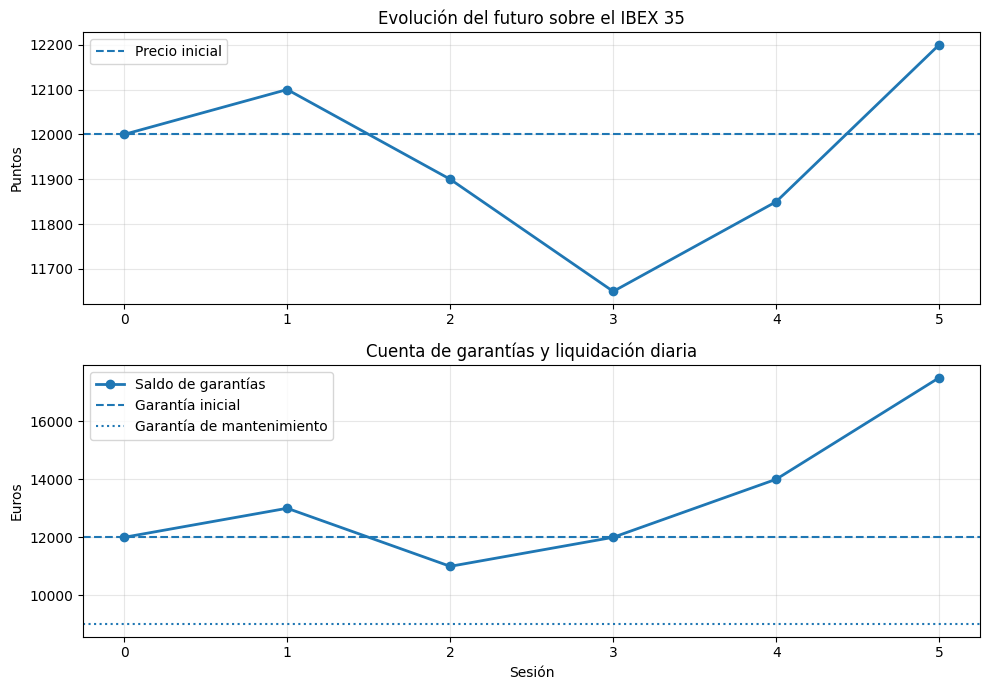

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(10, 7))

# Gráfico 1: evolución del precio del futuro
ax[0].plot(
    df["Sesión"],
    df["Precio futuro"],
    marker="o",
    linewidth=2
)

ax[0].axhline(
    precios[0],
    linestyle="--",
    label="Precio inicial"
)

ax[0].set_title("Evolución del futuro sobre el IBEX 35")
ax[0].set_ylabel("Puntos")
ax[0].legend()
ax[0].grid(alpha=0.3)

# Gráfico 2: evolución del saldo de garantías
ax[1].plot(
    df["Sesión"],
    df["Saldo garantías (€)"],
    marker="o",
    linewidth=2,
    label="Saldo de garantías"
)

ax[1].axhline(
    garantia_inicial,
    linestyle="--",
    label="Garantía inicial"
)

ax[1].axhline(
    garantia_mantenimiento,
    linestyle=":",
    label="Garantía de mantenimiento"
)

ax[1].set_title("Cuenta de garantías y liquidación diaria")
ax[1].set_xlabel("Sesión")
ax[1].set_ylabel("Euros")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


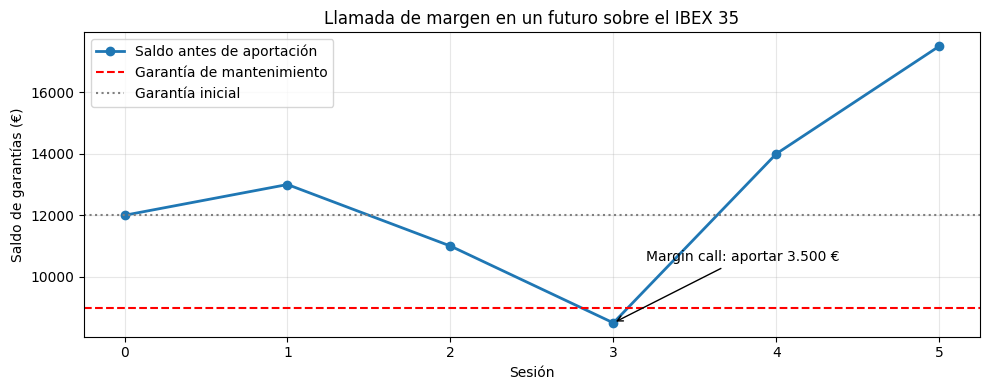

In [7]:
# Saldo antes de realizar cada aportación adicional
df["Saldo antes de aportación (€)"] = (
    df["Saldo garantías (€)"] - df["Aportación margen (€)"]
)

plt.figure(figsize=(10, 4))

plt.plot(
    df["Sesión"],
    df["Saldo antes de aportación (€)"],
    marker="o",
    linewidth=2,
    label="Saldo antes de aportación"
)

plt.axhline(
    garantia_mantenimiento,
    color="red",
    linestyle="--",
    label="Garantía de mantenimiento"
)

plt.axhline(
    garantia_inicial,
    color="gray",
    linestyle=":",
    label="Garantía inicial"
)

# Destacar la llamada de margen del día 3
plt.annotate(
    "Margin call: aportar 3.500 €",
    xy=(3, 8500),
    xytext=(3.2, 10500),
    arrowprops=dict(arrowstyle="->")
)

plt.title("Llamada de margen en un futuro sobre el IBEX 35")
plt.xlabel("Sesión")
plt.ylabel("Saldo de garantías (€)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Linea de beneficio de un futuro comprador y vendedor

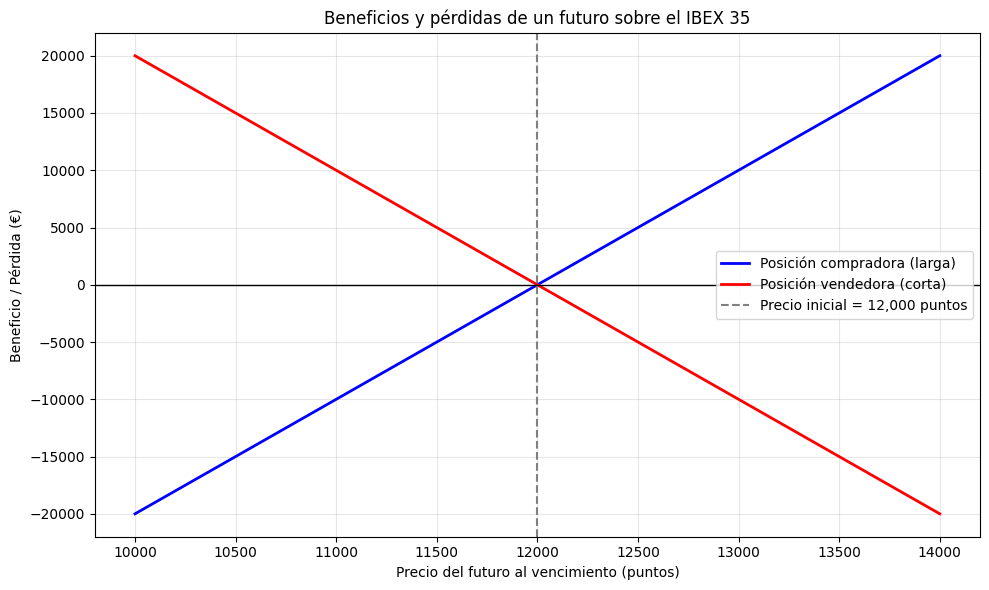

In [8]:
# Características del futuro sobre el IBEX 35
F0 = 12000           # Precio inicial del futuro
multiplicador = 10   # Euros por punto

# Posibles precios del futuro al vencimiento
FT = np.linspace(10000, 14000, 200)

# Beneficios de cada posición
beneficio_largo = (FT - F0) * multiplicador
beneficio_corto = (F0 - FT) * multiplicador

# Representación gráfica
plt.figure(figsize=(10, 6))

plt.plot(FT, beneficio_largo,
         label="Posición compradora (larga)",
         color="blue", linewidth=2)

plt.plot(FT, beneficio_corto,
         label="Posición vendedora (corta)",
         color="red", linewidth=2)

# Líneas de referencia
plt.axhline(0, color="black", linewidth=1)
plt.axvline(F0, color="gray", linestyle="--",
            label=f"Precio inicial = {F0:,} puntos")

# Formato
plt.title("Beneficios y pérdidas de un futuro sobre el IBEX 35")
plt.xlabel("Precio del futuro al vencimiento (puntos)")
plt.ylabel("Beneficio / Pérdida (€)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Estrategia de cobertura con futuros

**EJEMPLO:** Un fondo de inversión recibirá fondos dentro de tres meses y tiene previsto adquirir una cartera de acciones que reproduce el IBEX 35.

El gestor teme que el mercado suba antes de poder realizar la inversión.

La información disponible hoy es la siguiente:

Información disponible:

- IBEX 35 al contado $S_0$:	12.000 puntos
- Tipo de interés libre de riesgo anual $r$:	5 %
- Rentabilidad anual por dividendos $q$:	1 %
- Vencimiento $T$	3 meses: 0,25 años
- Multiplicador del futuro:	10 €/punto
- Contratos:	1
- Posición de cobertura:	Larga

Estrategia: comprar un futuro para compensar una posible subida del índice.

El precio del futuro vienen definido por:

$${F_{0,T}=S_0e^{(r-q)T}}$$

Sustituyendo:

$$F_{0,T}=12.000e^{(0,05-0,01)\times0,25}=12.120,60$$

El gestor compra un futuro a 12.120,60 puntos.

Dentro de tres meses, cuando reciba los fondos, realizará dos operaciones:
- Comprará la cartera de acciones en el mercado de contado al precio vigente $S_T$.
- Cerrará su posición larga en futuros, cuyo resultado acumulado será $(F_T-F_0)\times10$.

Al vencimiento, el precio del futuro converge al precio de contado:

$$F_T=S_T$$

Por tanto, el coste neto de adquirir la cartera será:

$$C_T=10S_T-10(F_T-F_0)$$

$$C_T=10F_0=121.206,02€$$

El coste económico queda fijado, independientemente de cómo evolucione el índice, dentro de las hipótesis de cobertura perfecta.


IBEX al contado: 12,000.00 puntos
Precio teórico del futuro: 12,120.60 puntos
Base inicial (F-S): 120.60 puntos
Nominal del futuro: 121,206.02 €


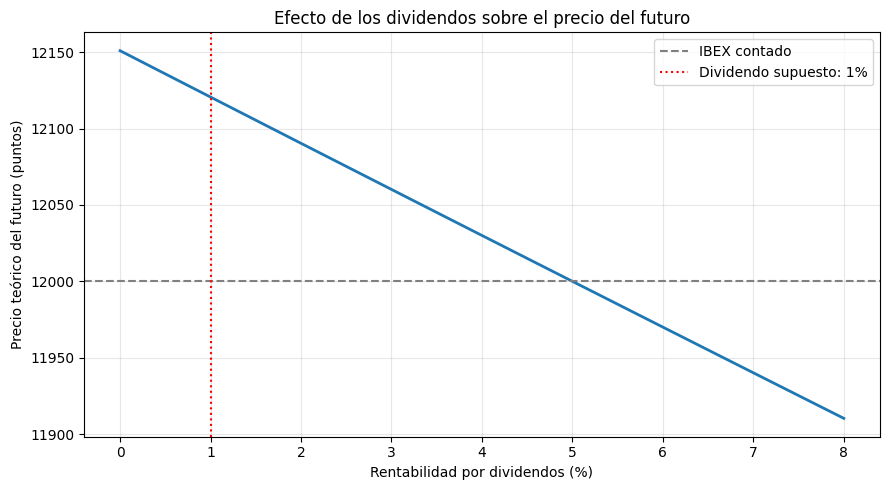

In [10]:
# VALORACIÓN DEL FUTURO
# Datos del mercado
S0 = 12000          # IBEX 35 al contado
r = 0.05            # Tipo de interés anual
q = 0.01            # Rentabilidad por dividendos anual
T = 3 / 12          # Vencimiento: 3 meses
M = 10              # Multiplicador del contrato

# Precio del futuro por ausencia de arbitraje
F0 = S0 * np.exp((r - q) * T)

print(f"IBEX al contado: {S0:,.2f} puntos")
print(f"Precio teórico del futuro: {F0:,.2f} puntos")
print(f"Base inicial (F-S): {F0-S0:,.2f} puntos")
print(f"Nominal del futuro: {F0*M:,.2f} €")

# Análisis de sensibilidad a los dividendos
dividendos = np.linspace(0, 0.08, 100)

precio_futuro = S0 * np.exp((r - dividendos) * T)

plt.figure(figsize=(9, 5))
plt.plot(dividendos * 100, precio_futuro, linewidth=2)
plt.axhline(S0, color="gray", linestyle="--",
            label="IBEX contado")
plt.axvline(q * 100, color="red", linestyle=":",
            label="Dividendo supuesto: 1%")

plt.title("Efecto de los dividendos sobre el precio del futuro")
plt.xlabel("Rentabilidad por dividendos (%)")
plt.ylabel("Precio teórico del futuro (puntos)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:

# Escenarios de variación del IBEX al vencimiento
variaciones = np.array([-0.20, -0.10, 0, 0.10, 0.20])

# IBEX al vencimiento
ST = S0 * (1 + variaciones)

# Convergencia entre futuro y contado al vencimiento
FT = ST

# Coste de comprar la cartera
coste_contado = ST * M

# Resultado acumulado del futuro largo
resultado_futuro = (FT - F0) * M

# Coste económico con cobertura
coste_cubierto = coste_contado - resultado_futuro

# Tabla de resultados
df = pd.DataFrame({
    "Variación IBEX (%)": variaciones * 100,
    "IBEX al vencimiento": ST,
    "Coste contado (€)": coste_contado,
    "PyG futuro (€)": resultado_futuro,
    "Coste cubierto (€)": coste_cubierto
})

display(df.round(2))


,Variación IBEX (%),IBEX al vencimiento,Coste contado (€),PyG futuro (€),Coste cubierto (€)
0,-20.0,9600.0,96000.0,-25206.02,121206.02
1,-10.0,10800.0,108000.0,-13206.02,121206.02
2,0.0,12000.0,120000.0,-1206.02,121206.02
3,10.0,13200.0,132000.0,10793.98,121206.02
4,20.0,14400.0,144000.0,22793.98,121206.02


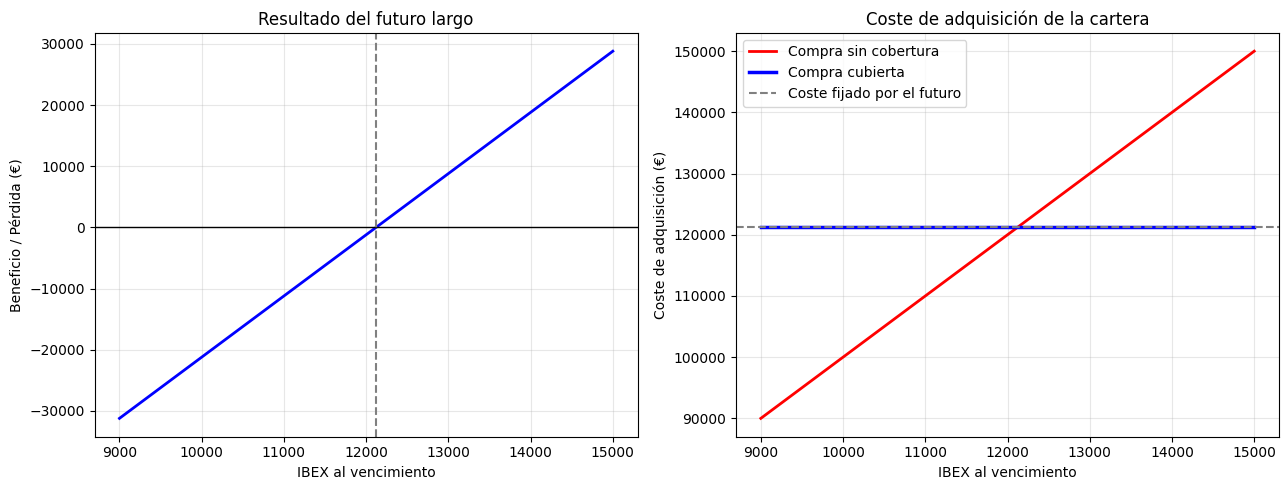

In [12]:

# Escenarios continuos para los gráficos
ST = np.linspace(9000, 15000, 200)
FT = ST

coste_contado = ST * M
resultado_futuro = (FT - F0) * M
coste_cubierto = coste_contado - resultado_futuro

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: ganancias y pérdidas del futuro
ax[0].plot(ST, resultado_futuro,
           color="blue", linewidth=2)
ax[0].axhline(0, color="black", linewidth=1)
ax[0].axvline(F0, color="gray", linestyle="--")
ax[0].set_title("Resultado del futuro largo")
ax[0].set_xlabel("IBEX al vencimiento")
ax[0].set_ylabel("Beneficio / Pérdida (€)")
ax[0].grid(alpha=0.3)

# Gráfico 2: resultado de la cobertura
ax[1].plot(ST, coste_contado,
           label="Compra sin cobertura",
           color="red", linewidth=2)

ax[1].plot(ST, coste_cubierto,
           label="Compra cubierta",
           color="blue", linewidth=2.5)

ax[1].axhline(F0*M, color="gray", linestyle="--",
              label="Coste fijado por el futuro")

ax[1].set_title("Coste de adquisición de la cartera")
ax[1].set_xlabel("IBEX al vencimiento")
ax[1].set_ylabel("Coste de adquisición (€)")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


**EJEMPLO** Un inversor tiene una cartera de acciones que replica el IBEX 35, valorada actualmente en 120.000 €. Dentro de tres meses tiene que realizar un pago de 120.000 €, que financiará vendiendo las participaciones de su cartera. Teme que el mercado bursátil caiga antes de esa fecha.

Para protegerse, vende un contrato de futuros sobre el IBEX 35. Sin embargo, el contrato disponible vence dentro de cuatro meses, mientras que el pago debe realizarse dentro de tres meses.

- Valor actual de la cartera:	120.000 €
- IBEX 35 $S_0$:	12.000 puntos
- Tipo de interés libre de riesgo, $r$:	5 % anual
- Rentabilidad por dividendos, $q$:	1 % anual
- Vencimiento del futuro, $T$:	4 meses
- Fecha del pago, $t$:	3 meses
- Obligación de pago:	120.000 €
- Multiplicador del futuro	10 €/punto

Estrategia: vender un futuro para compensar una posible caída del índice.

In [13]:
# Valoración del futuro

# 1. Datos iniciales
S0 = 12000
r = 0.05
q = 0.01
T = 4/12         # Vencimiento del futuro
t = 3/12         # Fecha de la obligación
M = 10
obligacion = 120000

# 2. Precio del futuro hoy (4 meses)
F0 = S0 * np.exp((r-q)*T)

print(f"Precio inicial del futuro: {F0:,.2f}")


Precio inicial del futuro: 12,161.07


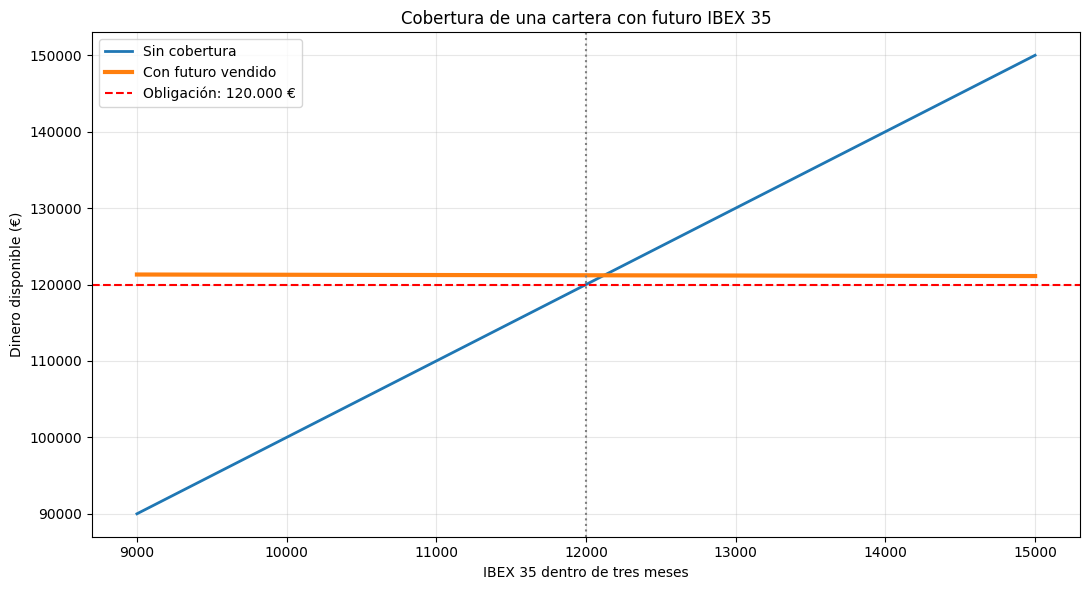

In [14]:
# 3. Escenarios del IBEX dentro de 3 meses
S3 = np.linspace(9000, 15000, 200)

# 4. Precio del futuro al cerrar la cobertura
# Al futuro todavía le queda un mes
F3 = S3 * np.exp((r-q)*(T-t))

# 5. Valor de la cartera de acciones
valor_cartera = S3 * M

# 6. Resultado de vender el futuro y recomprarlo
resultado_futuro = (F0-F3)*M

# 7. Dinero disponible para pagar la obligación
sin_cobertura = valor_cartera
con_cobertura = valor_cartera + resultado_futuro

# 8. Representación
plt.figure(figsize=(11, 6))

plt.plot(S3, sin_cobertura,
         label="Sin cobertura", linewidth=2)

plt.plot(S3, con_cobertura,
         label="Con futuro vendido", linewidth=3)

plt.axhline(obligacion, color="red",
            linestyle="--",
            label="Obligación: 120.000 €")

plt.axvline(S0, color="gray", linestyle=":")

plt.title("Cobertura de una cartera con futuro IBEX 35")
plt.xlabel("IBEX 35 dentro de tres meses")
plt.ylabel("Dinero disponible (€)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Riesgo base

Podemos escribir el resultado de la cobertura como:

$$W_3=MF_{0,4}-Mb_3$$


donde:
- $M$ es la cantidad de futuros adquiridos
- $F_{0,4}$ es el precio del futuro con vencimiento a 4 meses en el momento inicial
- $b_3=F_{3,4}-S_3$ es el riesgo base, siendo $F_{3,4}$ el valor del futuro con vencimiento a 4 meses transcurrido 3 meses.

Con el modelo de valoración empleado:

$$b_3=S_3\left(e^{(r-q)/12}-1\right)$$

**EJEMPLO:**
Vamos a mantener el ejemplo anterior, pero introduciendo una modificación en los tipos de interés durante la vida del contrato. Esto nos permitirá demostrar que una variación de los tipos de interés puede alterar el resultado de una cobertura con futuros, aunque el valor de la cartera al contado sea exactamente el mismo.

Supongamos que, transcurridos tres meses, el IBEX ha caído un 10 %:

$$S_3=10.800$$

La cartera vale ahora:

$$V_3=10.800\times10=108.000\text{ €}$$

Por tanto, el inversor necesita recuperar los 12.000 € que ha perdido la cartera para poder afrontar íntegramente la obligación.

Pero el futuro todavía tiene un mes hasta su vencimiento. Su precio de cierre dependerá del tipo de interés aplicable a ese mes.

Vamos a considerar tres escenarios:
- Escenario A: el tipo de interés baja del 5 % al 3 %.
- Escenario B: el tipo de interés permanece en el 5 %.
- Escenario C: el tipo de interés sube del 5 % al 7 %.

Mantenemos constante la rentabilidad esperada por dividendos del 1 % y el nivel del IBEX en 10.800 puntos.

El precio del futuro en el mes 3 será:

$$F_{3,4}=10.800e^{(r_3-0,01)/12}$$


,Tipo de interés (%),Precio futuro,Valor cartera (€),Beneficio futuro (€),Importe total (€)
0,3.0,10818.02,108000,13430.56,121430.56
1,5.0,10836.06,108000,13250.11,121250.11
2,7.0,10854.14,108000,13069.36,121069.36


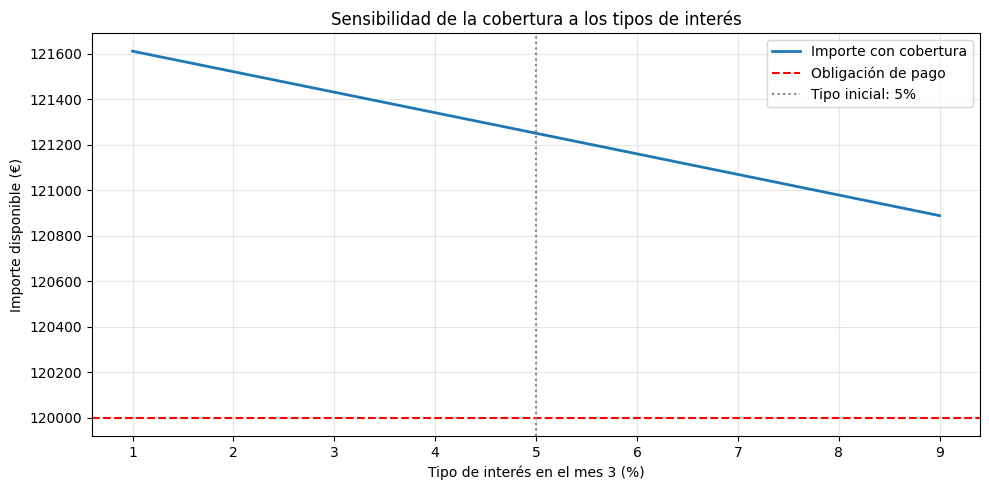

In [15]:
# Datos iniciales
S0 = 12000
r0 = 0.05
q = 0.01
T = 4/12
t = 3/12
M = 10

# Precio inicial del futuro
F0 = S0 * np.exp((r0-q)*T)

# IBEX a los tres meses: caída del 10%
S3 = 10800

# Escenarios de tipos de interés
tipos = np.array([0.03, 0.05, 0.07])

# Precio del futuro al cerrar la cobertura
F3 = S3 * np.exp((tipos-q)*(T-t))

# Resultado del futuro corto
beneficio_futuro = (F0-F3)*M

# Valor de la cartera
valor_cartera = S3*M

# Resultado conjunto
importe_total = valor_cartera + beneficio_futuro

df = pd.DataFrame({
    "Tipo de interés (%)": tipos*100,
    "Precio futuro": F3,
    "Valor cartera (€)": valor_cartera,
    "Beneficio futuro (€)": beneficio_futuro,
    "Importe total (€)": importe_total
})

display(df.round(2))

# Gráfico de sensibilidad
rango_tipos = np.linspace(0.01, 0.09, 100)

F3_sim = S3*np.exp((rango_tipos-q)*(T-t))
importe_sim = valor_cartera + (F0-F3_sim)*M

plt.figure(figsize=(10, 5))

plt.plot(rango_tipos*100, importe_sim,
         linewidth=2,
         label="Importe con cobertura")

plt.axhline(120000, color="red",
            linestyle="--",
            label="Obligación de pago")

plt.axvline(5, color="gray",
            linestyle=":",
            label="Tipo inicial: 5%")

plt.title("Sensibilidad de la cobertura a los tipos de interés")
plt.xlabel("Tipo de interés en el mes 3 (%)")
plt.ylabel("Importe disponible (€)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
